In [8]:
import os 
import sys 

import cv2 
import numpy as np 
import pandas as pd

import seaborn as sns 
import matplotlib.pylab as plt 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder  

sys.path.append(os.path.abspath('..'))

from src.config.config import VALID_EXTENSIONS, IMG_SIZE

In [2]:
count = 0 

labels = [ ]
images = [ ]

for root, dirs, files in os.walk('../data') : 

    for file in files : 

        file_path = os.path.join(root, file)

        if not file.lower().endswith(VALID_EXTENSIONS) : 
            os.remove(file_path)
            count += 1
            continue 

        try : 
            img = cv2.imread(file_path )

            img = cv2.resize(img, IMG_SIZE)

            images.append(img)
            labels.append(os.path.basename(root))
        except cv2.error : 
            os.remove(file_path)
            count += 1
            continue

        

In [3]:
print("Nombre d'images :", len(images))
print("Nombre de labels :", len(labels))

Nombre d'images : 7023
Nombre de labels : 7023


In [6]:
images = np.array(images, dtype=np.float32) / 255.0 

array([2000, 1757, 1645, 1621])

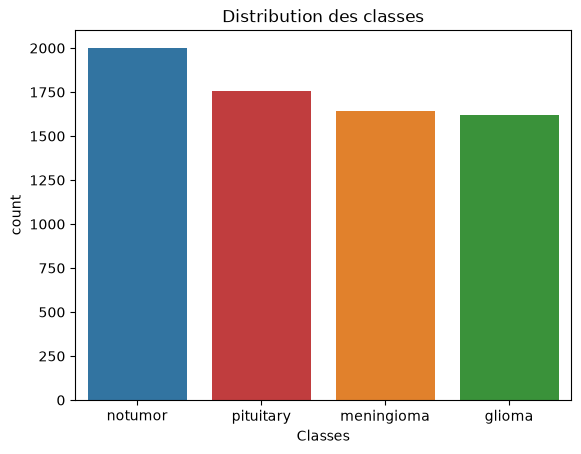

In [18]:
sns.countplot(x=labels, order=pd.Series(labels).value_counts().index , hue=labels) 
plt.title("Distribution des classes")
plt.xlabel("Classes")

plt.show()

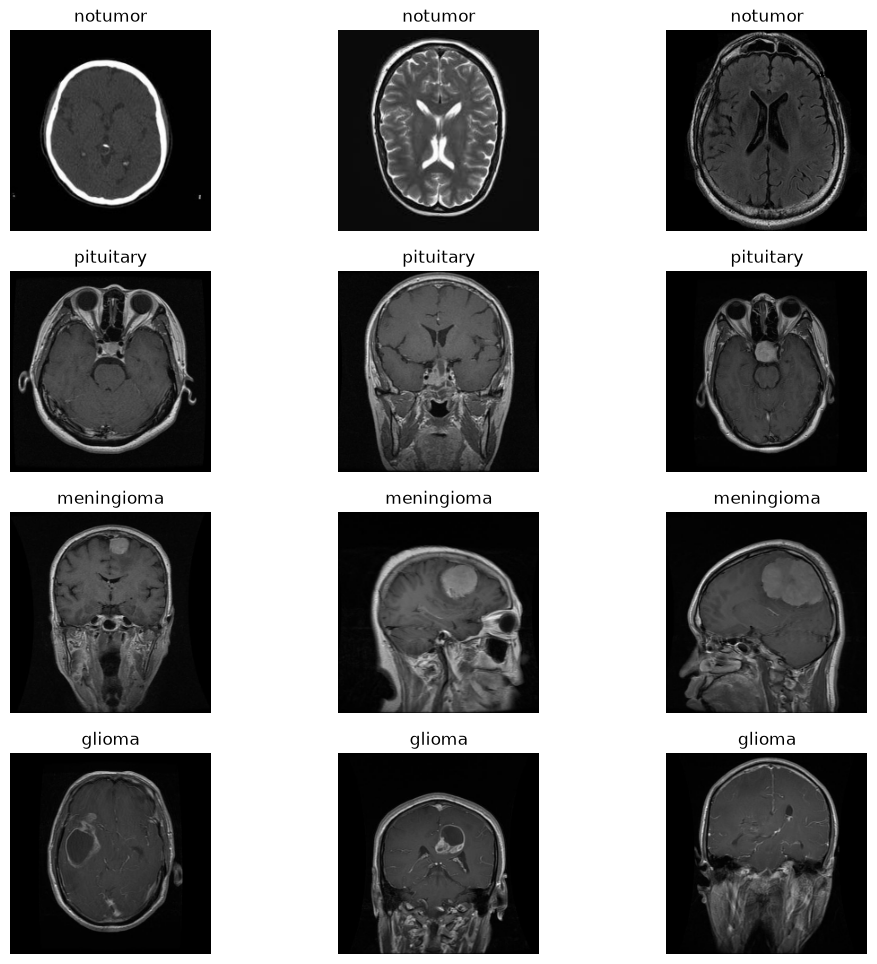

In [19]:
fig , axes = plt.subplots(4, 3, figsize=(12, 12))

# i want get the first 3 from evry class and plot them ?  can you help me with that ? 

for i, label in enumerate(pd.Series(labels).value_counts().index) :
    label_images = [images[j] for j in range(len(labels)) if labels[j] == label ] 

    for j in range(3) : 
        axes[i, j].imshow(label_images[j])
        axes[i, j].set_title(label)
        axes[i, j].axis('off')


In [ ]:
labels = LabelEncoder().fit_transform(labels)

Index([2, 3, 1, 0], dtype='int64')

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)